<a href="https://colab.research.google.com/github/KasianDmitroFIT3-9-lab/numpy-lab-1/blob/main/%D0%9B%D1%804_%D0%9A%D0%B0%D1%81%D1%8F%D0%BD_%D0%94_%D0%A4%D0%86%D0%A23_9__ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота №4. Регресійні моделі: глибоке дослідження

**Датасет:** Car Price Prediction Multiple Linear Regression  
https://www.kaggle.com/datasets/hellbuoy/car-price-prediction?select=CarPrice_Assignment.csv

**Мета роботи:** виконати підготовку даних, побудувати та порівняти регресійні моделі для прогнозування ціни автомобіля, оцінити їх якість і проаналізувати отримані результати.

> У шаблоні наведено лише умови завдань. Реалізацію необхідно виконати самостійно у порожніх комірках.


## 1. Завантаження та первинний аналіз даних

Завантажити датасет та виконати його первинний огляд:
- визначити кількість об'єктів і ознак;
- переглянути назви стовпців;
- визначити типи даних;
- визначити цільову змінну;
- вивести основні статистичні характеристики даних.


In [33]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("hellbuoy/car-price-prediction")

print("Path to dataset files:", path)


Using Colab cache for faster access to the 'car-price-prediction' dataset.
Path to dataset files: /kaggle/input/car-price-prediction


In [34]:

import kagglehub
import pandas as pd
import numpy as np
import os

path = kagglehub.dataset_download("hellbuoy/car-price-prediction")
df = pd.read_csv(os.path.join(path, "CarPrice_Assignment.csv"))

print("Дані завантажено!")
print("Розмір таблиці:", df.shape)
display(df.head())


Using Colab cache for faster access to the 'car-price-prediction' dataset.
Дані завантажено!
Розмір таблиці: (205, 26)


,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,1,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0
1,2,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0
2,3,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0
3,4,2,audi 100 ls,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0
4,5,2,audi 100ls,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0


In [35]:

car_ids = df["car_ID"].copy()
df_model = df.drop(columns=["car_ID"]).copy()

from sklearn.model_selection import train_test_split

X = df_model.drop(columns=["price"])
y = df_model["price"]

X_train, X_test, y_train, y_test, id_train, id_test = train_test_split(
    X, y, car_ids,
    test_size=0.2,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)


X_train: (164, 24)
X_test: (41, 24)


In [36]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PowerTransformer, StandardScaler, OneHotEncoder

continuous_cols = [
    col for col in X_train.select_dtypes(include=np.number).columns
    if col != "symboling"
]

discrete_cols = ["symboling"]

categorical_cols = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

continuous_pipeline = Pipeline([
    ("yeo_johnson", PowerTransformer(method="yeo-johnson")),
    ("scaler", StandardScaler())
])

discrete_pipeline = Pipeline([
    ("scaler", StandardScaler())
])

categorical_pipeline = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

preprocessor = ColumnTransformer([
    ("continuous", continuous_pipeline, continuous_cols),
    ("discrete", discrete_pipeline, discrete_cols),
    ("categorical", categorical_pipeline, categorical_cols)
])

print("Preprocessor успішно створено!")


Preprocessor успішно створено!


In [37]:

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Обробку даних завершено!")
print("Розмір train:", X_train_processed.shape)
print("Розмір test:", X_test_processed.shape)


Обробку даних завершено!
Розмір train: (164, 175)
Розмір test: (41, 175)


In [38]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

csv_files = [
    f for f in os.listdir(path)
    if f.endswith('.csv')
]

print("Знайдені CSV-файли:", csv_files)


Знайдені CSV-файли: ['CarPrice_Assignment.csv']


In [39]:

from sklearn.model_selection import train_test_split

X = df_model.drop(columns=['price'])
y = df_model['price']

X_train, X_test, y_train, y_test, id_train, id_test = train_test_split(
    X, y, car_ids,
    test_size=0.2,
    random_state=42
)

# Повторна обробка викидів за правилом IQR
continuous_cols = [
    col for col in X_train.select_dtypes(include=np.number).columns
    if col != 'symboling'
]

outlier_bounds = {}

for col in continuous_cols:
    Q1 = X_train[col].quantile(0.25)
    Q3 = X_train[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outlier_bounds[col] = (lower, upper)

X_train = X_train.copy()
X_test = X_test.copy()

for col, (lower, upper) in outlier_bounds.items():
    X_train[col] = X_train[col].clip(lower=lower, upper=upper)
    X_test[col] = X_test[col].clip(lower=lower, upper=upper)

print("Навчальну й тестову вибірки відновлено!")
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)


Навчальну й тестову вибірки відновлено!
X_train: (164, 24)
X_test: (41, 24)
y_train: (164,)
y_test: (41,)


In [40]:

df = pd.read_csv(os.path.join(path, 'CarPrice_Assignment.csv'))

print("Перші 5 рядків:")
display(df.head())

print("Розмір датасету:", df.shape)

print("\nНазви стовпців:")
print(df.columns.tolist())

print("\nТипи даних:")
print(df.dtypes)

print("\nЦільова змінна: price")

print("\nОсновні статистичні характеристики:")
display(df.describe(include='all').T)


Перші 5 рядків:


,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,1,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0
1,2,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0
2,3,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0
3,4,2,audi 100 ls,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0
4,5,2,audi 100ls,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0


Розмір датасету: (205, 26)

Назви стовпців:
['car_ID', 'symboling', 'CarName', 'fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'wheelbase', 'carlength', 'carwidth', 'carheight', 'curbweight', 'enginetype', 'cylindernumber', 'enginesize', 'fuelsystem', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg', 'price']

Типи даних:
car_ID                int64
symboling             int64
CarName              object
fueltype             object
aspiration           object
doornumber           object
carbody              object
drivewheel           object
enginelocation       object
wheelbase           float64
carlength           float64
carwidth            float64
carheight           float64
curbweight            int64
enginetype           object
cylindernumber       object
enginesize            int64
fuelsystem           object
boreratio           float64
stroke              float64
compressionratio    float64
horsepower

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
car_ID,205.0,NaN,NaN,NaN,103.0,59.322565,1.0,52.0,103.0,154.0,205.0
symboling,205.0,NaN,NaN,NaN,0.834146,1.245307,-2.0,0.0,1.0,2.0,3.0
CarName,205,147,peugeot 504,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN
fueltype,205,2,gas,185,NaN,NaN,NaN,NaN,NaN,NaN,NaN
aspiration,205,2,std,168,NaN,NaN,NaN,NaN,NaN,NaN,NaN
doornumber,205,2,four,115,NaN,NaN,NaN,NaN,NaN,NaN,NaN
carbody,205,5,sedan,96,NaN,NaN,NaN,NaN,NaN,NaN,NaN
drivewheel,205,3,fwd,120,NaN,NaN,NaN,NaN,NaN,NaN,NaN
enginelocation,205,2,front,202,NaN,NaN,NaN,NaN,NaN,NaN,NaN
wheelbase,205.0,NaN,NaN,NaN,98.756585,6.021776,86.6,94.5,97.0,102.4,120.9


In [41]:

print('df:', 'df' in globals())
print('df_model:', 'df_model' in globals())
print('car_ids:', 'car_ids' in globals())


df: True
df_model: True
car_ids: True


In [42]:

import kagglehub

path = kagglehub.dataset_download("hellbuoy/car-price-prediction")

print("Шлях до датасету:", path)


Using Colab cache for faster access to the 'car-price-prediction' dataset.
Шлях до датасету: /kaggle/input/car-price-prediction


In [43]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

csv_files = [f for f in os.listdir(path) if f.endswith('.csv')]
print("Знайдені CSV-файли:", csv_files)

df = pd.read_csv(os.path.join(path, 'CarPrice_Assignment.csv'))

print("Розмір датасету:", df.shape)
display(df.head())


Знайдені CSV-файли: ['CarPrice_Assignment.csv']
Розмір датасету: (205, 26)


,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,1,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0
1,2,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0
2,3,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0
3,4,2,audi 100 ls,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0
4,5,2,audi 100ls,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0


In [44]:

car_ids = df['car_ID'].copy()
df_model = df.drop(columns=['car_ID']).copy()

print("df:", df.shape)
print("df_model:", df_model.shape)
print("car_ids:", len(car_ids))


df: (205, 26)
df_model: (205, 25)
car_ids: 205


## 2. Перевірка якості даних

Перевірити:
- наявність пропущених значень;
- наявність повних дублікатів;
- кількість унікальних значень в ознаках.

Під час аналізу врахувати, що `car_ID` є унікальним ідентифікатором автомобіля і сам по собі не повинен використовуватися для визначення дублікатів за змістовими характеристиками.


In [45]:

# 1. Перевірка пропущених значень
print("=== Пропущені значення ===")
print(df.isnull().sum())

# 2. Перевірка повних дублікатів
print("\n=== Повні дублікати ===")
print("Кількість:", df.duplicated().sum())

# 3. Перевірка дублікатів без урахування car_ID
print("\n=== Дублікати за характеристиками без car_ID ===")
df_without_id = df.drop(columns=['car_ID'])
print("Кількість:", df_without_id.duplicated().sum())

# 4. Кількість унікальних значень в ознаках
print("\n=== Унікальні значення ===")
print(df.nunique())


=== Пропущені значення ===
car_ID              0
symboling           0
CarName             0
fueltype            0
aspiration          0
doornumber          0
carbody             0
drivewheel          0
enginelocation      0
wheelbase           0
carlength           0
carwidth            0
carheight           0
curbweight          0
enginetype          0
cylindernumber      0
enginesize          0
fuelsystem          0
boreratio           0
stroke              0
compressionratio    0
horsepower          0
peakrpm             0
citympg             0
highwaympg          0
price               0
dtype: int64

=== Повні дублікати ===
Кількість: 0

=== Дублікати за характеристиками без car_ID ===
Кількість: 0

=== Унікальні значення ===
car_ID              205
symboling             6
CarName             147
fueltype              2
aspiration            2
doornumber            2
carbody               5
drivewheel            3
enginelocation        2
wheelbase            53
carlength          

## 3. Робота з car_ID

Зберегти `car_ID` окремо для подальшої ідентифікації автомобілів у результатах прогнозування.  
Не використовувати `car_ID` як ознаку під час навчання моделей.


In [46]:

# Зберігаємо ідентифікатори автомобілів окремо
car_ids = df['car_ID'].copy()

# Створюємо копію датасету без car_ID
df_model = df.drop(columns=['car_ID']).copy()

print("Перші 10 ідентифікаторів автомобілів:")
print(car_ids.head(10).tolist())

print("\nРозмір початкового датасету:", df.shape)
print("Розмір даних без car_ID:", df_model.shape)

print("\nЧи залишився car_ID серед ознак?")
print('car_ID' in df_model.columns)


Перші 10 ідентифікаторів автомобілів:
[1, 2, 3, 4, 5, 6, 7, 8, 9, 10]

Розмір початкового датасету: (205, 26)
Розмір даних без car_ID: (205, 25)

Чи залишився car_ID серед ознак?
False


In [47]:
car_ids = df['car_ID'].copy()
df_model = df.drop(columns=['car_ID']).copy()

print("df_model:", df_model.shape)
print("car_ids:", len(car_ids))

df_model: (205, 25)
car_ids: 205


## 4. Дослідження розподілів числових ознак

Дослідити розподіли числових ознак:
- побудувати відповідні графіки;
- обчислити коефіцієнти асиметрії;
- визначити ознаки з найбільш вираженою асиметрією;
- коротко прокоментувати отримані результати.


Числові ознаки:
['symboling', 'wheelbase', 'carlength', 'carwidth', 'carheight', 'curbweight', 'enginesize', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg', 'price']

Коефіцієнти асиметрії (від найбільшої абсолютної до найменшої):


,Коефіцієнт асиметрії
compressionratio,2.610862
enginesize,1.947655
price,1.777678
horsepower,1.405310
wheelbase,1.050214
carwidth,0.904003
stroke,-0.689705
curbweight,0.681398
citympg,0.663704
highwaympg,0.539997


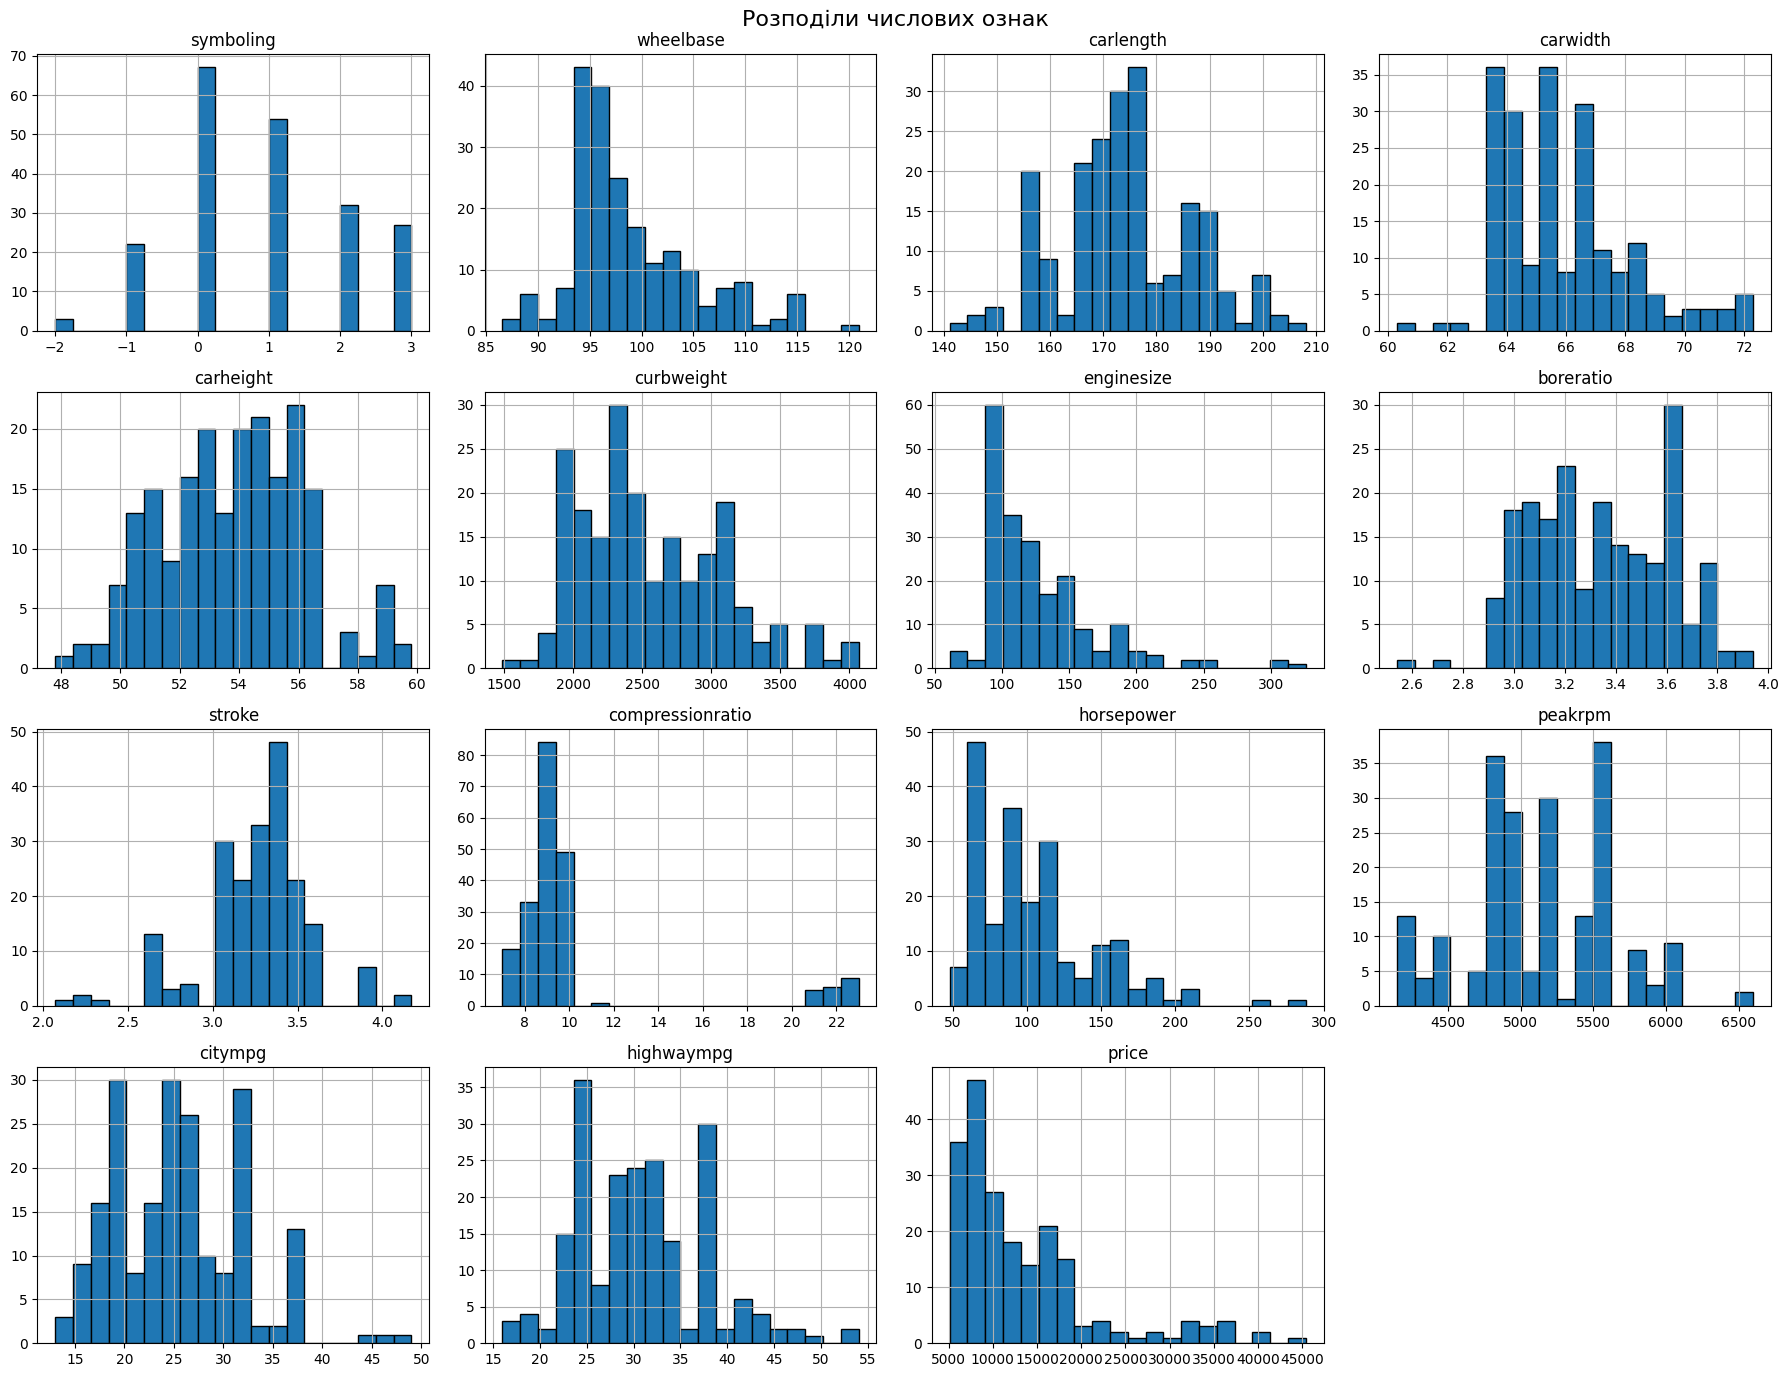


П'ять ознак із найбільшою абсолютною асиметрією:


,Коефіцієнт асиметрії
compressionratio,2.610862
enginesize,1.947655
price,1.777678
horsepower,1.405310
wheelbase,1.050214


In [48]:

# Вибираємо числові ознаки
numeric_cols = df_model.select_dtypes(include=np.number).columns.tolist()

print("Числові ознаки:")
print(numeric_cols)

# Обчислюємо коефіцієнти асиметрії
skew_values = df_model[numeric_cols].skew()
skew_sorted = skew_values.reindex(
    skew_values.abs().sort_values(ascending=False).index
)

print("\nКоефіцієнти асиметрії (від найбільшої абсолютної до найменшої):")
display(skew_sorted.to_frame(name='Коефіцієнт асиметрії'))

# Будуємо гістограми розподілів
df_model[numeric_cols].hist(
    figsize=(18, 14),
    bins=20,
    edgecolor='black'
)

plt.suptitle("Розподіли числових ознак", fontsize=16)
plt.tight_layout()
plt.show()

# Виводимо п'ять ознак із найбільшою асиметрією
print("\nП'ять ознак із найбільшою абсолютною асиметрією:")
display(skew_sorted.head(5).to_frame(name='Коефіцієнт асиметрії'))


## 5. Формування train/test вибірок

Відокремити цільову змінну `price` від ознак та розділити дані на:
- навчальну вибірку — 80%;
- тестову вибірку — 20%.

Забезпечити відтворюваність поділу.  
Окремо зберегти `car_ID` для об'єктів, які потрапили до train і test.

**Важливо:** усі подальші параметри передобробки даних визначати тільки за навчальною вибіркою.


In [49]:

from sklearn.model_selection import train_test_split

# Відокремлюємо ознаки від цільової змінної
X = df_model.drop(columns=['price'])
y = df_model['price']

# Ділимо дані: 80% для навчання, 20% для тестування
X_train, X_test, y_train, y_test, id_train, id_test = train_test_split(
    X,
    y,
    car_ids,
    test_size=0.2,
    random_state=42
)

print("Розмір навчальної вибірки X_train:", X_train.shape)
print("Розмір тестової вибірки X_test:", X_test.shape)

print("\nРозмір y_train:", y_train.shape)
print("Розмір y_test:", y_test.shape)

print("\nКількість автомобілів у train:", len(id_train))
print("Кількість автомобілів у test:", len(id_test))

print("\nПерші 5 ID з train:")
print(id_train.head().tolist())

print("\nПерші 5 ID з test:")
print(id_test.head().tolist())


Розмір навчальної вибірки X_train: (164, 24)
Розмір тестової вибірки X_test: (41, 24)

Розмір y_train: (164,)
Розмір y_test: (41,)

Кількість автомобілів у train: 164
Кількість автомобілів у test: 41

Перші 5 ID з train:
[67, 112, 154, 97, 39]

Перші 5 ID з test:
[16, 10, 101, 133, 69]


In [50]:

# Відновлюємо змінні для подальшої роботи
car_ids = df['car_ID'].copy()
df_model = df.drop(columns=['car_ID']).copy()

print("Дані відновлено!")
print("Розмір df_model:", df_model.shape)
print("Кількість ID:", len(car_ids))


Дані відновлено!
Розмір df_model: (205, 25)
Кількість ID: 205


## 6. Аналіз та обробка викидів

Для неперервних числових ознак навчальної вибірки:
- визначити потенційні викиди методом IQR;
- вивести кількість потенційних викидів для кожної ознаки;
- обґрунтувати спосіб їх обробки.

Для невеликого набору даних не видаляти автоматично всі рядки з викидами. Використати обмеження крайніх значень межами, визначеними за навчальною вибіркою.

Цільову змінну `price` не використовувати для визначення меж викидів.  
До тестової вибірки застосувати ті самі межі, які були отримані за train.


In [51]:

# Визначаємо неперервні числові ознаки навчальної вибірки
# symboling є дискретною ознакою, а price — цільовою змінною
continuous_cols = X_train.select_dtypes(include=np.number).columns.tolist()
continuous_cols.remove('symboling')

print("Неперервні числові ознаки:")
print(continuous_cols)

# Визначаємо межі IQR тільки за навчальною вибіркою
outlier_bounds = {}

print("\nКількість потенційних викидів у train:")

for col in continuous_cols:
    Q1 = X_train[col].quantile(0.25)
    Q3 = X_train[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outlier_bounds[col] = (lower, upper)

    count = ((X_train[col] < lower) | (X_train[col] > upper)).sum()
    print(f"{col}: {count}")

# Обмежуємо крайні значення межами, визначеними за train
X_train = X_train.copy()
X_test = X_test.copy()

for col, (lower, upper) in outlier_bounds.items():
    X_train[col] = X_train[col].clip(lower=lower, upper=upper)
    X_test[col] = X_test[col].clip(lower=lower, upper=upper)

print("\nОбробку викидів завершено.")
print("Розмір X_train:", X_train.shape)
print("Розмір X_test:", X_test.shape)


Неперервні числові ознаки:
['wheelbase', 'carlength', 'carwidth', 'carheight', 'curbweight', 'enginesize', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg']

Кількість потенційних викидів у train:
wheelbase: 6
carlength: 0
carwidth: 10
carheight: 0
curbweight: 0
enginesize: 7
boreratio: 1
stroke: 16
compressionratio: 20
horsepower: 7
peakrpm: 2
citympg: 0
highwaympg: 1

Обробку викидів завершено.
Розмір X_train: (164, 24)
Розмір X_test: (41, 24)


## 7. Аналіз кореляцій та відбір ознак

За навчальною вибіркою:
- побудувати матрицю кореляцій числових ознак;
- знайти пари ознак із сильною кореляцією, для яких `|r| > 0.85`;
- для кожної такої пари залишити одну ознаку;
- під час вибору врахувати силу зв'язку кожної ознаки з цільовою змінною `price`;
- вивести список сильно корельованих пар та перелік ознак, які видаляються.

Із тестової вибірки видалити ті самі ознаки.  
Не використовувати тестову вибірку для прийняття рішення про відбір ознак.


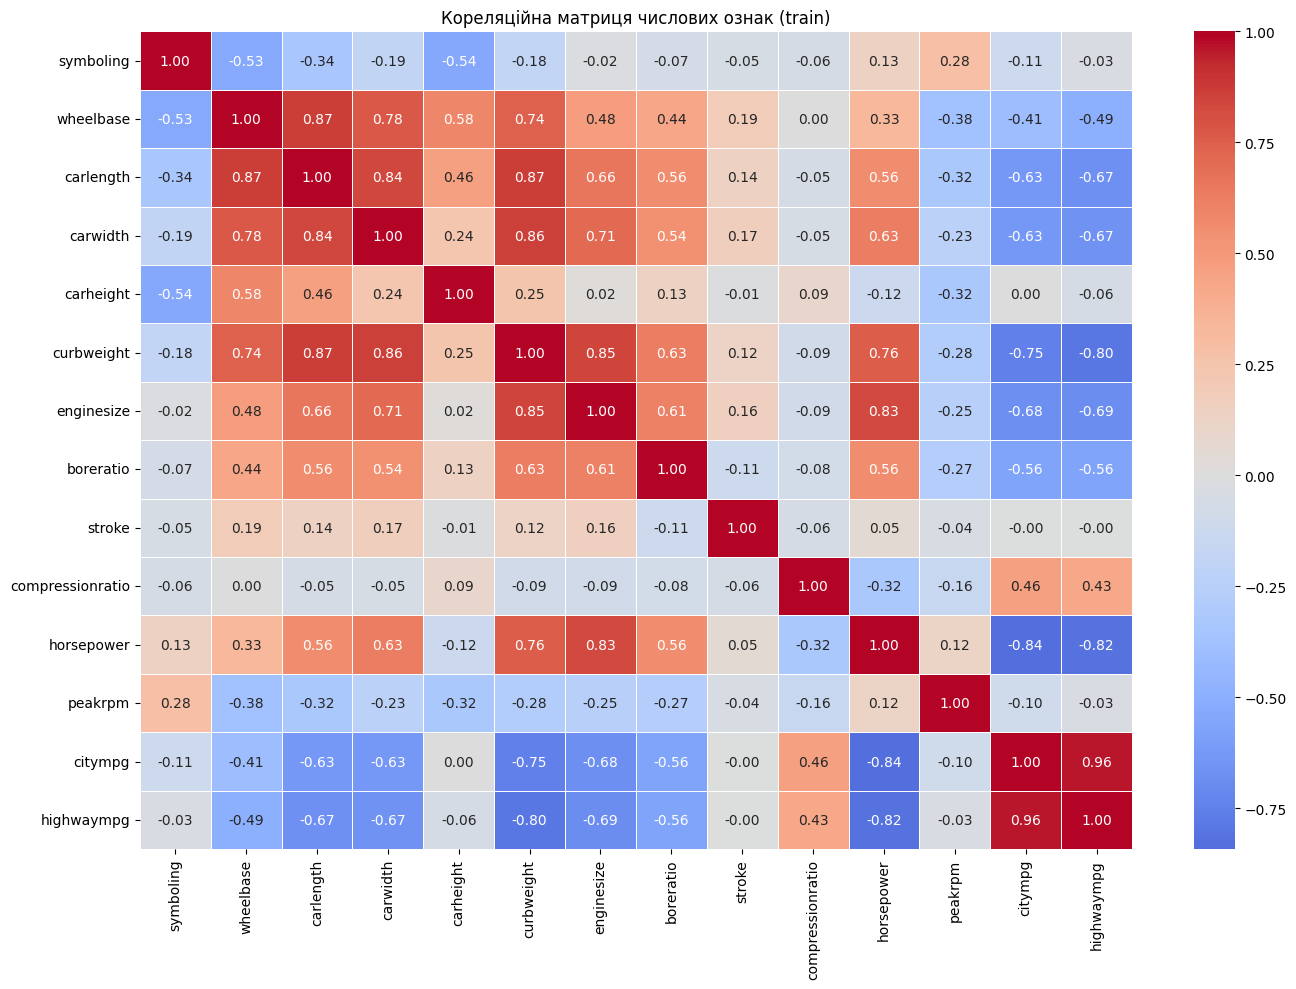

Пари ознак із кореляцією |r| > 0.85:
wheelbase — carlength: 0.867
carlength — curbweight: 0.866
carwidth — curbweight: 0.858
citympg — highwaympg: 0.964


In [52]:

# Беремо тільки числові ознаки навчальної вибірки
numeric_train = X_train.select_dtypes(include=np.number)

# Обчислюємо кореляційну матрицю
corr_matrix = numeric_train.corr()

# Візуалізуємо кореляції
plt.figure(figsize=(14, 10))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    center=0,
    fmt='.2f',
    linewidths=0.5
)
plt.title("Кореляційна матриця числових ознак (train)")
plt.tight_layout()
plt.show()

# Знаходимо пари ознак із сильною кореляцією
threshold = 0.85
strong_corr = []

for i in range(len(corr_matrix.columns)):
    for j in range(i + 1, len(corr_matrix.columns)):
        corr_value = corr_matrix.iloc[i, j]
        if abs(corr_value) > threshold:
            strong_corr.append((
                corr_matrix.columns[i],
                corr_matrix.columns[j],
                corr_value
            ))

print("Пари ознак із кореляцією |r| > 0.85:")
if strong_corr:
    for col1, col2, value in strong_corr:
        print(f"{col1} — {col2}: {value:.3f}")
else:
    print("Таких пар не знайдено.")


## 8. Підготовка числових і категоріальних ознак

Розділити ознаки на:
- неперервні числові;
- дискретну числову ознаку `symboling`;
- категоріальні.

Для неперервних числових ознак виконати послідовно:
1. перетворення Yeo–Johnson для зменшення асиметрії;
2. масштабування за допомогою StandardScaler.

Для `symboling` виконати масштабування без Yeo–Johnson.

Категоріальні ознаки закодувати методом One-Hot Encoding. Передбачити коректну обробку категорій у test, яких не було у train.

Усі перетворення об'єднати в єдиний механізм передобробки даних, який навчається тільки на `X_train`.


In [53]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PowerTransformer, StandardScaler, OneHotEncoder

# Визначаємо типи ознак
continuous_cols = [
    col for col in X_train.select_dtypes(include=np.number).columns
    if col != 'symboling'
]
discrete_cols = ['symboling']
categorical_cols = X_train.select_dtypes(
    include=['object', 'category']
).columns.tolist()

# Для неперервних ознак: Yeo-Johnson + стандартизація
continuous_pipeline = Pipeline([
    ('yeo_johnson', PowerTransformer(method='yeo-johnson')),
    ('scaler', StandardScaler())
])

# Для symboling: лише стандартизація
discrete_pipeline = Pipeline([
    ('scaler', StandardScaler())
])

# Для категоріальних ознак: One-Hot Encoding
categorical_pipeline = OneHotEncoder(
    handle_unknown='ignore',
    sparse_output=False
)

# Об'єднуємо всі перетворення
preprocessor = ColumnTransformer([
    ('continuous', continuous_pipeline, continuous_cols),
    ('discrete', discrete_pipeline, discrete_cols),
    ('categorical', categorical_pipeline, categorical_cols)
])

print("Конвеєр попередньої обробки створено.")
print("Неперервних ознак:", len(continuous_cols))
print("Дискретних ознак:", len(discrete_cols))
print("Категоріальних ознак:", len(categorical_cols))



Конвеєр попередньої обробки створено.
Неперервних ознак: 13
Дискретних ознак: 1
Категоріальних ознак: 10


## 9. Перевірка трансформації числових ознак

Перевірити результат трансформації неперервних числових ознак:
- застосувати до train ту саму послідовність перетворень, яка буде використана в моделях;
- повторно обчислити коефіцієнти асиметрії;
- порівняти їх із початковими значеннями;
- зробити короткий висновок щодо ефективності трансформації.


In [67]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Обробку даних завершено!")
print("Розмір обробленого train:", X_train_processed.shape)
print("Розмір обробленого test:", X_test_processed.shape)
print("Чи є NaN у train:", np.isnan(X_train_processed).any())
print("Чи є NaN у test:", np.isnan(X_test_processed).any())


Обробку даних завершено!
Розмір обробленого train: (164, 175)
Розмір обробленого test: (41, 175)
Чи є NaN у train: False
Чи є NaN у test: False


In [55]:

import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

path = kagglehub.dataset_download("hellbuoy/car-price-prediction")
df = pd.read_csv(os.path.join(path, "CarPrice_Assignment.csv"))

car_ids = df["car_ID"].copy()
df_model = df.drop(columns=["car_ID"]).copy()

print("Датасет:", df.shape)
print("Дані для моделювання:", df_model.shape)


Using Colab cache for faster access to the 'car-price-prediction' dataset.
Датасет: (205, 26)
Дані для моделювання: (205, 25)


## 10. Побудова регресійних моделей

Побудувати та навчити такі моделі:
- Linear Regression;
- Ridge Regression;
- Lasso Regression;
- Random Forest Regressor;
- Gradient Boosting Regressor;
- Support Vector Regressor (SVR).

Для кожної моделі створити єдиний Pipeline, який містить:
1. попередню обробку ознак;
2. відповідну регресійну модель.

Використати однакову схему підготовки даних для коректного порівняння моделей.


In [66]:
feature_names = preprocessor.get_feature_names_out()

print("Кількість ознак після обробки:", len(feature_names))
print("\nПерші 20 назв ознак:")
print(feature_names[:20])

print("\nПерші 5 рядків обробленої навчальної вибірки:")
display(pd.DataFrame(
    X_train_processed,
    columns=feature_names
).head())

print("\nТип даних після обробки:", X_train_processed.dtype)


Кількість ознак після обробки: 175

Перші 20 назв ознак:
['continuous__wheelbase' 'continuous__carlength' 'continuous__carwidth'
 'continuous__carheight' 'continuous__curbweight' 'continuous__enginesize'
 'continuous__boreratio' 'continuous__stroke'
 'continuous__compressionratio' 'continuous__horsepower'
 'continuous__peakrpm' 'continuous__citympg' 'continuous__highwaympg'
 'discrete__symboling' 'categorical__CarName_Nissan versa'
 'categorical__CarName_alfa-romero Quadrifoglio'
 'categorical__CarName_alfa-romero giulia'
 'categorical__CarName_alfa-romero stelvio'
 'categorical__CarName_audi 100 ls' 'categorical__CarName_audi 100ls']

Перші 5 рядків обробленої навчальної вибірки:


,continuous__wheelbase,continuous__carlength,continuous__carwidth,continuous__carheight,continuous__curbweight,continuous__enginesize,continuous__boreratio,continuous__stroke,continuous__compressionratio,continuous__horsepower,...,categorical__cylindernumber_twelve,categorical__cylindernumber_two,categorical__fuelsystem_1bbl,categorical__fuelsystem_2bbl,categorical__fuelsystem_4bbl,categorical__fuelsystem_idi,categorical__fuelsystem_mfi,categorical__fuelsystem_mpfi,categorical__fuelsystem_spdi,categorical__fuelsystem_spfi
0,1.126424,0.118969,0.212478,0.283461,0.455778,0.533925,0.416981,1.300337,2.237721,-0.952208,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
1,1.463353,1.044803,1.226386,1.203945,1.063079,0.118697,0.527121,-2.762239,-0.614440,0.026479,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2,-0.420073,-0.328392,-1.281702,2.151912,-0.439830,-1.140230,-1.007290,-0.772646,-0.021696,-1.577154,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
3,-0.701205,-0.714357,-1.121611,0.323736,-1.320157,-0.856356,-0.627056,0.040374,0.291186,-1.122582,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
4,-0.245060,-0.519664,-0.214430,-0.161118,-0.417480,-0.250065,-0.627056,1.070289,-0.021696,-0.300215,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0



Тип даних після обробки: float64


## 11. Оцінювання якості моделей

Для кожної моделі:
- виконати навчання на тренувальній вибірці;
- отримати прогноз для тестової вибірки;
- обчислити метрики **R², MAE, MSE та MAPE**.

`MAPE` подати у відсотках.

Результати всіх моделей об'єднати в одну порівняльну таблицю та впорядкувати за значенням R² від найбільшого до найменшого.

Під час інтерпретації врахувати:
- R² — чим більше, тим краще;
- MAE, MSE, MAPE — чим менше, тим краще.


In [65]:

# Завдання 11. Навчання та оцінювання моделей

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error
)

models = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Lasso": Lasso(alpha=0.1, max_iter=10000),
    "Random Forest": RandomForestRegressor(
        n_estimators=200, random_state=42
    ),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
    "SVR": SVR()
}

trained_models = {}
predictions = {}
results = []

for name, model in models.items():
    # Навчання
    model.fit(X_train_processed, y_train)
    trained_models[name] = model

    # Прогноз
    y_pred = model.predict(X_test_processed)
    predictions[name] = y_pred

    # Метрики якості
    results.append({
        "Модель": name,
        "R²": r2_score(y_test, y_pred),
        "MAE": mean_absolute_error(y_test, y_pred),
        "MSE": mean_squared_error(y_test, y_pred),
        "MAPE (%)": mean_absolute_percentage_error(y_test, y_pred) * 100
    })

# Порівняльна таблиця: від найбільшого R² до найменшого
results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    by="R²", ascending=False
).reset_index(drop=True)

print("Результати оцінювання моделей:")
display(results_df.round(3))

print("Кількість навчених моделей:", len(trained_models))
print("Кількість наборів прогнозів:", len(predictions))


Результати оцінювання моделей:


,Модель,R²,MAE,MSE,MAPE (%)
0,Random Forest,0.954,1349.363,3.592878e+06,9.901
1,Gradient Boosting,0.931,1702.028,5.471918e+06,12.573
2,Ridge,0.767,2795.292,1.841034e+07,25.278
3,Lasso,0.563,3636.076,3.450560e+07,25.544
4,Linear Regression,0.528,4057.964,3.723057e+07,29.511
5,SVR,-0.100,5694.490,8.680527e+07,36.000


Кількість навчених моделей: 6
Кількість наборів прогнозів: 6


## 12. Пояснення вибору типу моделі

Пояснити, чому класифікаційна модель, наприклад Logistic Regression, не підходить для безпосереднього прогнозування неперервної ціни автомобіля.

Зазначити, до якого типу задачі належить прогнозування `price` та чому моделі, використані в роботі, відповідають цій задачі.


### Завдання 12. Пояснення вибору типу моделі

Прогнозування ціни автомобіля (`price`) належить до задачі **регресії**, оскільки ціна є неперервною числовою величиною. Метою є отримання конкретного числового значення ціни на основі характеристик автомобіля.

Класифікаційна модель, наприклад Logistic Regression, призначена для визначення класу або категорії об'єкта, а не для безпосереднього прогнозування неперервної ціни. Наприклад, класифікація могла б визначати, чи належить автомобіль до категорії «дешевий», «середній» або «дорогий», але не прогнозувала б його точну ціну.

У роботі використано регресійні моделі, зокрема Linear Regression, Ridge, Lasso, Random Forest Regressor та Gradient Boosting Regressor. Вони підходять для прогнозування числових значень, дають змогу оцінювати залежність ціни від характеристик автомобіля та порівнювати точність отриманих прогнозів за метриками R², MAE, MSE і MAPE.

## 13. Візуальне порівняння прогнозів

Для кожної побудованої моделі зобразити співвідношення:
- фактичних значень `price`;
- прогнозованих значень `price`.

Додати лінію ідеального прогнозу та проаналізувати, наскільки близько до неї розташовані прогнозовані значення. Звернути увагу на великі відхилення.


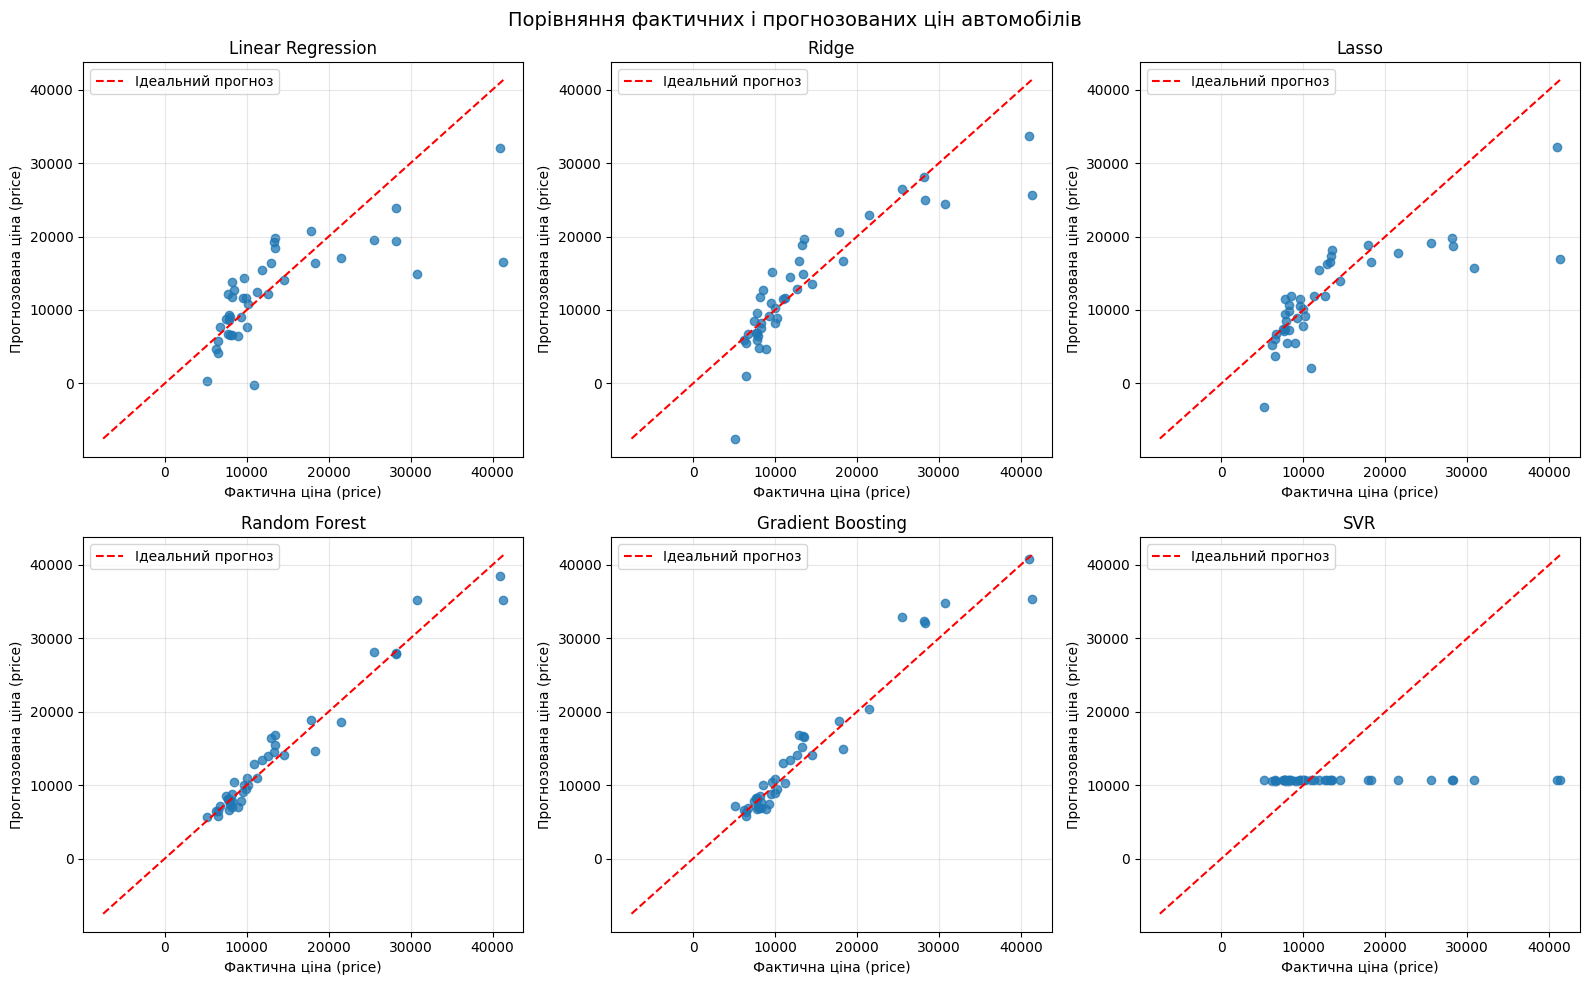

In [64]:

# Завдання 13. Фактичні та прогнозовані ціни

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

min_price = min(
    float(y_test.min()),
    min(float(np.min(pred)) for pred in predictions.values())
)
max_price = max(
    float(y_test.max()),
    max(float(np.max(pred)) for pred in predictions.values())
)

for ax, (name, y_pred) in zip(axes, predictions.items()):
    ax.scatter(y_test, y_pred, alpha=0.75)

    # Лінія ідеального прогнозу
    ax.plot(
        [min_price, max_price],
        [min_price, max_price],
        "r--",
        label="Ідеальний прогноз"
    )

    ax.set_title(name)
    ax.set_xlabel("Фактична ціна (price)")
    ax.set_ylabel("Прогнозована ціна (price)")
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.suptitle(
    "Порівняння фактичних і прогнозованих цін автомобілів",
    fontsize=14
)
plt.tight_layout()
plt.show()


In [63]:

variables = [
    "df", "X_train", "X_test", "y_train", "y_test",
    "preprocessor", "X_train_processed", "X_test_processed",
    "trained_models", "predictions"
]

for name in variables:
    print(f"{name}: {name in globals()}")


df: True
X_train: True
X_test: True
y_train: True
y_test: True
preprocessor: True
X_train_processed: True
X_test_processed: True
trained_models: True
predictions: True


## 14. Прогноз для 10 автомобілів

Випадково вибрати 10 автомобілів із тестової вибірки.

За допомогою моделі Random Forest отримати для них прогноз ціни та сформувати таблицю з такими даними:
- `car_ID`;
- фактична ціна;
- прогнозована ціна;
- абсолютна помилка;
- абсолютна відсоткова помилка.

Прокоментувати отримані результати.


In [59]:


rng = np.random.default_rng(42)

selected_positions = rng.choice(
    len(X_test), size=10, replace=False
)

y_actual = y_test.iloc[selected_positions]
car_id_10 = id_test.iloc[selected_positions]

y_pred_10 = rf_model.predict(
    X_test_processed[selected_positions]
)

absolute_error = np.abs(y_actual.to_numpy() - y_pred_10)
percentage_error = absolute_error / np.abs(y_actual.to_numpy()) * 100

results_10 = pd.DataFrame({
    "car_ID": car_id_10.to_numpy(),
    "Фактична ціна": y_actual.to_numpy(),
    "Прогнозована ціна": y_pred_10,
    "Абсолютна помилка": absolute_error,
    "Абсолютна відсоткова помилка (%)": percentage_error
})

display(results_10.round(2))


,car_ID,Фактична ціна,Прогнозована ціна,Абсолютна помилка,Абсолютна відсоткова помилка (%)
0,133,11850.0,13483.04,1633.04,13.78
1,17,41315.0,35185.29,6129.71,14.84
2,101,9549.0,9014.96,534.04,5.59
3,99,8249.0,7064.30,1184.70,14.36
4,153,6488.0,6414.92,73.07,1.13
5,70,28176.0,33867.24,5691.24,20.20
6,196,13415.0,16811.02,3396.01,25.32
7,147,7463.0,8529.26,1066.26,14.29
8,148,10198.0,9960.96,237.04,2.32
9,121,6229.0,6439.58,210.59,3.38


In [61]:

import kagglehub
import pandas as pd
import numpy as np
import os

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PowerTransformer, StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestRegressor

# 1. Завантаження даних
path = kagglehub.dataset_download("hellbuoy/car-price-prediction")
df = pd.read_csv(os.path.join(path, "CarPrice_Assignment.csv"))

car_ids = df["car_ID"].copy()
df_model = df.drop(columns=["car_ID"]).copy()

X = df_model.drop(columns=["price"])
y = df_model["price"]

# 2. Розподіл на навчальну та тестову вибірки
X_train, X_test, y_train, y_test, id_train, id_test = train_test_split(
    X, y, car_ids, test_size=0.2, random_state=42
)

# 3. Попередня обробка ознак
continuous_cols = [
    col for col in X_train.select_dtypes(include=np.number).columns
    if col != "symboling"
]
discrete_cols = ["symboling"]
categorical_cols = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

continuous_pipeline = Pipeline([
    ("yeo_johnson", PowerTransformer(method="yeo-johnson")),
    ("scaler", StandardScaler())
])
discrete_pipeline = Pipeline([
    ("scaler", StandardScaler())
])
categorical_pipeline = OneHotEncoder(
    handle_unknown="ignore", sparse_output=False
)

preprocessor = ColumnTransformer([
    ("continuous", continuous_pipeline, continuous_cols),
    ("discrete", discrete_pipeline, discrete_cols),
    ("categorical", categorical_pipeline, categorical_cols)
])

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

# 4. Навчання Random Forest
rf_model = RandomForestRegressor(
    n_estimators=200, random_state=42
)
rf_model.fit(X_train_processed, y_train)

print("Дані та модель відновлені!")
print("X_test:", X_test.shape)
print("Тестові оброблені дані:", X_test_processed.shape)


Using Colab cache for faster access to the 'car-price-prediction' dataset.
Дані та модель відновлені!
X_test: (41, 24)
Тестові оброблені дані: (41, 175)


## 15. Висновки

Сформулювати підсумкові висновки за результатами роботи.

У висновках:
- порівняти якість усіх моделей;
- проаналізувати R², MAE, MSE і MAPE;
- зазначити, яка модель показала найкращі результати за отриманими метриками;
- прокоментувати величину похибок;
- звернути увагу на можливі ознаки перенавчання;
- коротко оцінити вплив попередньої обробки даних на результати моделювання.


### Висновок

Під час виконання лабораторної роботи №4 було досліджено методи побудови регресійних моделей для прогнозування вартості автомобілів на основі набору даних Car Price Prediction. Дані було підготовлено до аналізу, розділено на навчальну та тестову вибірки, а числові й категоріальні ознаки оброблено за допомогою інструментів бібліотеки Scikit-learn.

Було побудовано та порівняно шість моделей: Linear Regression, Ridge, Lasso, Random Forest, Gradient Boosting і SVR. Для оцінювання їхньої якості використано метрики R², MAE, MSE та MAPE.

Найкращий результат показала модель **Random Forest** з коефіцієнтом детермінації R² = 0,954, середньою абсолютною помилкою MAE = 1349,363 та середньою відсотковою помилкою MAPE = 9,901%. Друге місце посіла модель Gradient Boosting з R² = 0,931 і MAPE = 12,573%. Моделі Ridge, Lasso та Linear Regression продемонстрували нижчу точність, а SVR отримала від’ємне значення R² = −0,100, що свідчить про незадовільну якість прогнозування на тестовій вибірці.

Додатково за допомогою Random Forest було спрогнозовано вартість десяти автомобілів із тестової вибірки та обчислено абсолютні й відсоткові помилки прогнозів.

Отже, результати дослідження показали, що для цього набору даних модель Random Forest забезпечила найкращу якість прогнозування серед розглянутих алгоритмів. Під час роботи було закріплено навички підготовки даних, побудови регресійних моделей, оцінювання їхньої точності та порівняння результатів машинного навчання за допомогою Python і бібліотеки Scikit-learn.


## Загальні вимоги до виконання

- Не використовувати тестову вибірку для визначення меж викидів, кореляційного відбору ознак, навчання трансформерів, масштабування або кодування категорій.
- Усі параметри передобробки мають визначатися тільки за навчальною вибіркою.
- Фінальні метрики моделей обчислювати на тестовій вибірці.
- Не використовувати `car_ID` як предиктор.
- Не видаляти спостереження або ознаки без пояснення причини.
- До кожного основного етапу додати короткий змістовний висновок.
- У підсумкових висновках спиратися на отримані метрики та графіки.
